# Paper 09: PointNet: Deep Learning on Point Sets for 3D Classification and Segmentation
**Authors**: Charles R. Qi, Hao Su, Kaichun Mo, Leonidas J. Guibas (2017)

---

## 1. The Historical Breaking Point: The 3D Perception Crisis
Robots, LiDAR, and depth sensors perceive the physical world as **Point Clouds** $\{p_1, \dots, p_N\} \subset \mathbb{R}^3$.
Prior to PointNet, neural networks could not process raw point sets directly:
- **3D Voxelization (VoxNet)**: Discretizing 3D space into dense grids ($32^3$ or $128^3$) causes cubic memory explosion $O(V^3)$, massive sparsity ($>95\%$ empty air), and quantization loss.
- **Multi-View 2D Renderings**: Loses 3D geometry and cannot perform per-point manipulation or part segmentation.

## 2. The Universal Symmetric Approximation Theorem
Point clouds are **unordered sets**. A network processing points must be strictly **permutation invariant**:
$$f(p_{\pi(1)}, \dots, p_{\pi(N)}) = f(p_1, \dots, p_N)$$

Qi et al. proved that any continuous symmetric set function can be arbitrarily approximated by:
$$f(\{x_1, \dots, x_N\}) \approx \gamma \left( \max_{i=1 \dots N} \{ h(x_i) \} \right)$$

1. **Shared MLP $h$**: Maps each 3D point independently into a high-dimensional feature space ($3 \to 64 \to 128 \to 1024$).
2. **Symmetric Max-Pooling $\max$**: Collapses all $N$ points along the point dimension into a single 1024-dimensional global shape signature. Max-pooling is mathematically order-invariant!
3. **T-Net**: Mini spatial transformer network learning canonical 3D rotation and alignment.

In this notebook, you will test `TNet`, `PointNetEncoder`, `PointNetCls`, and `PointNetSeg` implemented in `model.py`.

---
## Setup
`%autoreload 2` automatically reloads your code from `model.py` whenever changes are saved.

In [20]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from model import TNet, PointNetEncoder, PointNetCls, PointNetSeg
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: T-Net & Permutation Invariance Proof

We verify:
1. `TNet`: Predicts a $(B, 3, 3)$ coordinate alignment matrix initialized near Identity.
2. **Permutation Invariance**: Shuffling the order of 512 points produces **identical** classification logits!

In [21]:
print("Testing T-Net Shape & Identity Initialization:")
tests.test_tnet_shape_and_initialization(TNet)

print("\nTesting Permutation Invariance (Order Independence):")
tests.test_permutation_invariance(PointNetCls)

Testing T-Net Shape & Identity Initialization:
  [PASS] T-Net outputs (B, 3, 3) matrix initialized near Identity (diff: 0.0000)!

Testing Permutation Invariance (Order Independence):
  [PASS] Permutation Invariance Proven: shuffling 512 points produced identical logits (diff: 0.00e+00)!


True

---
## Part 2: 3D Classification & Part Segmentation

We verify:
1. 3D Shape Classification forward pass: $(B, 3, N) \to (B, 40)$.
2. 3D Part Segmentation forward pass: $(B, 3, N) \to (B, 16, N)$.
3. **Single-Batch 3D Overfit Gate**: Rapid convergence on a toy 3D point cloud classification task.

In [26]:
print("Testing Classification & Part Segmentation Shapes:")
tests.test_classification_and_segmentation_shapes(PointNetCls, PointNetSeg)

print("\nTesting Single-Batch 3D Overfit Gate:")
tests.test_single_batch_overfit(PointNetCls)

Testing Classification & Part Segmentation Shapes:
  [PASS] PointNetCls forward pass matches (B, num_classes) = (2, 40)!
  [PASS] PointNetSeg per-point segmentation matches (B, num_classes, N) = (2, 16, 256)!

Testing Single-Batch 3D Overfit Gate:
  [PASS] Single-batch 3D point cloud overfit passed (loss: 1.2798 -> 0.000605)!


True

---
## Part 3: 3D Point Cloud Visualization

Let's visualize a synthetic 3D point cloud of a geometric object (a 3D torus with 1,024 points) and inspect its coordinate distribution.

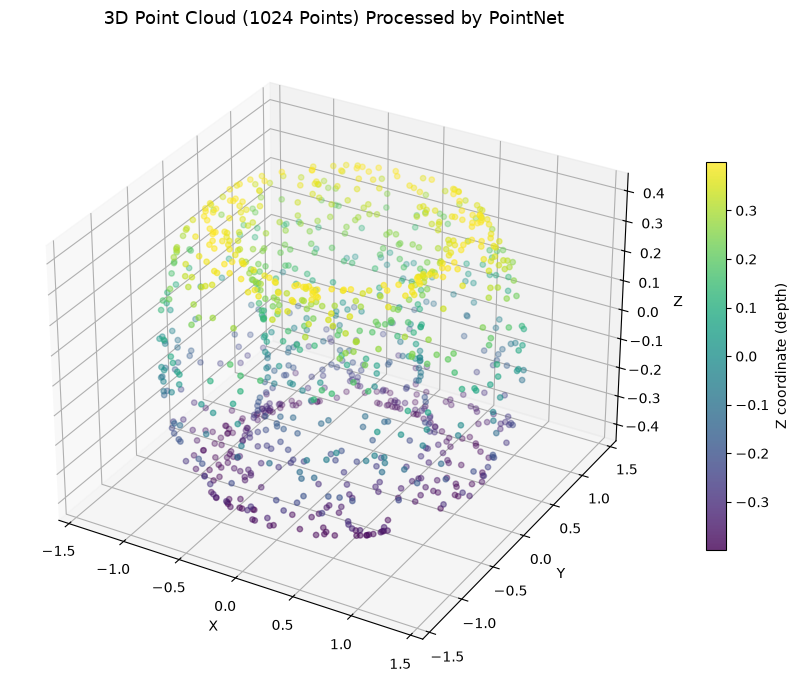

Point cloud shape: torch.Size([1, 3, 1024]) | Predicted Logits shape: torch.Size([1, 10])


In [27]:
torch.manual_seed(42)
N = 1024

# Generate 3D Torus points
theta = torch.rand(N) * 2 * math.pi
phi = torch.rand(N) * 2 * math.pi
R, r = 1.0, 0.4

x = (R + r * torch.cos(theta)) * torch.cos(phi)
y = (R + r * torch.cos(theta)) * torch.sin(phi)
z = r * torch.sin(theta)

points = torch.stack([x, y, z], dim=0).unsqueeze(0) # (1, 3, 1024)

# Pass through PointNetCls
model = PointNetCls(num_classes=10)
model.eval()
with torch.no_grad():
    logits, trans, _ = model(points)

# 3D Visualization
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
p = ax.scatter(x.numpy(), y.numpy(), z.numpy(), c=z.numpy(), cmap='viridis', s=15, alpha=0.8)
fig.colorbar(p, ax=ax, label='Z coordinate (depth)', shrink=0.6)
ax.set_title(f'3D Point Cloud ({N} Points) Processed by PointNet', fontsize=13)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

print(f"Point cloud shape: {points.shape} | Predicted Logits shape: {logits.shape}")